# Differential Equations in Astronomy — the Friedmann Equations

**Author:** Margarita Tsvetkova \
**Menthor:** Svetlana Kolyakina, Head of Science Department in Letovo School \
**Date:** 13.05.2025

**Goals of the project**

1. Derive the Friedmann equation from Newton's law of gravitation.
2. Solve it for the scale factor $a(t)$ analytically (matter-dominated case) and numerically (Euler, RK4).
3. Compare the numerical methods with the analytical solution and measure their order of accuracy.
4. Plot the relative size of the Universe as a function of cosmic time for several cosmological models.
5. Compute the present age of the Universe.


## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp

plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 11,
})
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK = "#333333"

G   = 6.674e-11          # m^3 kg^-1 s^-2
c   = 2.998e8            # m/s
Mpc = 3.0857e22          # m
Gyr = 1e9 * 365.25 * 86400  # s (Julian year)

def H0_to_per_Gyr(H0_kms_Mpc):
    "Convert H0 from km/s/Mpc to 1/Gyr."
    return H0_kms_Mpc * 1e3 / Mpc * Gyr

print(f"H0 = 67.4 km/s/Mpc = {H0_to_per_Gyr(67.4):.5f} Gyr^-1")
print(f"Hubble time 1/H0  = {1/H0_to_per_Gyr(67.4):.3f} Gyr")

H0 = 67.4 km/s/Mpc = 0.06893 Gyr^-1
Hubble time 1/H0  = 14.507 Gyr


## 1. Introductory concepts

Assumptions:

* **Cosmological principle** — the Universe is homogeneous and isotropic. Any point can be treated as "the centre".
* **Perfect fluid** — matter and energy are modelled as a fluid with density $\rho$ and pressure $p$ linked by an equation of state.
* **General relativity** describes gravity. (Below, the same equation is obtained from Newtonian gravity, which works because a small sphere in a homogeneous Universe behaves Newtonianly.)
* **Cosmological constant.** The Newtonian derivation gives no $\Lambda$ term; we add it later because observations require dark energy.

### FLRW metric

$$
ds^2 = c^2\,dt^2 - a(t)^2\left(\frac{dr^2}{1-kr^2} + r^2\,d\Omega^2\right),
\qquad d\Omega^2 = d\theta^2 + \sin^2\theta\,d\phi^2 .
$$


Here $a(t)$ is the scale factor, $k \in \{-1, 0, +1\}$ the curvature constant (open, flat, closed), and $r,\theta,\phi$ are comoving coordinates.

### Parameters

| Symbol | Meaning |
|---|---|
| $E_p,\;E_k$ | potential and kinetic energy of a test particle |
| $a(t)$ | scale factor, normalised so $a_0 = a(t_0) = 1$ today; $a<1$ in the past, $a>1$ in the future |
| $H(t) = \dot a/a$ | Hubble parameter; $H_0$ is its present value |
| $k$ | curvature constant |
| $\rho_m,\;\rho_r,\;\rho_\Lambda$ | matter, radiation, dark-energy density |
| $\Omega_i = \rho_i/\rho_\text{crit}$ | density parameters |

## 2. Mathematical part

### 2.1 Newtonian derivation of the Friedmann equation

Take a test particle of mass $m$ at distance $R$ from an arbitrary point. By the shell theorem only the mass inside the sphere of radius $R$ acts on it:

$$M = \tfrac{4}{3}\pi R^3 \rho .$$

$$
F = \frac{GMm}{R^2} = \frac{4\pi G\rho R m}{3}, \tag{1}
$$
$$
E_p = -\frac{GMm}{R} = -\frac{4\pi G \rho R^2 m}{3}, \tag{2}
$$
$$
E_k = \frac{m\dot R^2}{2}. \tag{3}
$$


Energy conservation:

$$
E = \frac12 m\dot R^2 - \frac{4\pi}{3} G\rho R^2 m = \text{const}.
$$


Switch to comoving coordinates, $\vec R = a(t)\,\vec x$ with $\vec x$ constant:

$$
E = \frac12 m\dot a^2 x^2 - \frac{4\pi}{3} G \rho a^2 x^2 m .
$$

Multiply by $\dfrac{2}{m a^2 x^2}$:

$$
\frac{2E}{m a^2 x^2} = \frac{\dot a^2}{a^2} - \frac{8\pi G}{3}\rho
\quad\Longrightarrow\quad
\left(\frac{\dot a}{a}\right)^2 = \frac{8\pi G}{3}\rho + \frac{2E}{m a^2 x^2}.
$$

Homogeneity requires the last term to be independent of the particle we picked, so $E \propto x^2$ and we may define a constant

$$
kc^2 \equiv -\frac{2E}{m x^2}
\qquad\Longrightarrow\qquad
\boxed{\;H^2 = \left(\frac{\dot a}{a}\right)^2 = \frac{8\pi G}{3}\rho - \frac{kc^2}{a^2}\;}
$$


### 2.2 Hubble's law

The physical velocity of a comoving galaxy is

$$
\vec v = \dot{\vec R} = \dot a\,\vec x = \frac{\dot a}{a}\,\vec R = H\,\vec R ,
$$

so the **recession** velocity grows linearly with distance and $H = \dot a / a$.

A least-squares fit through the origin to six galaxies gives $H_0$ directly as the slope:

H0 (fit)   = 68.7 ± 1.4 km/s/Mpc
1/H0       = 14.24 Gyr   (Hubble time)


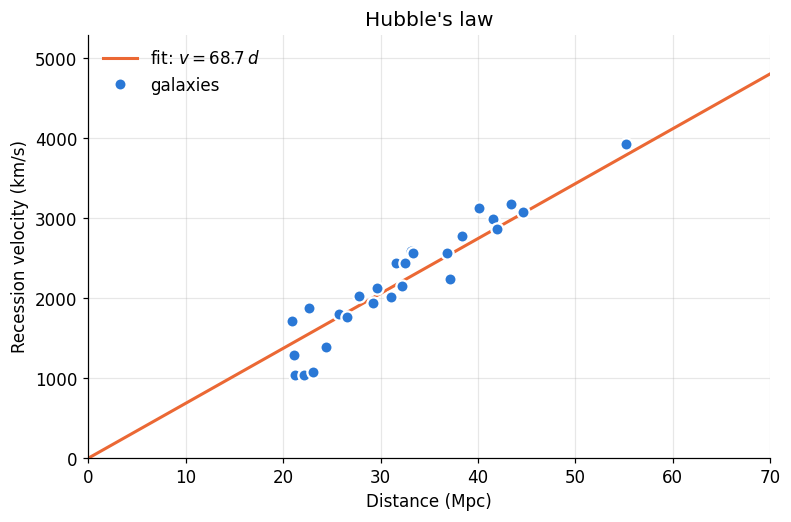

In [7]:
# Cepheid distance moduli (Riess et al. 2022) and recession velocities v = c*z_HD
# from the Pantheon+SH0ES data release (Scolnic et al. 2022; Brout et al. 2022)
galaxies = ['NGC 4038', 'NGC 7250', 'NGC 3972', 'NGC 3982', 'NGC 5584', 'NGC 4639', 'NGC 3447',
            'NGC 2525', 'NGC 3370', 'NGC 5861', 'NGC 3254', 'NGC 5917', 'NGC 3021', 'NGC 7541',
            'NGC 1309', 'NGC 1015', 'NGC 4680', 'NGC 2608', 'NGC 691', 'UGC 9391', 'Mrk 1337',
            'NGC 3147', 'NGC 5728', 'NGC 5468', 'NGC 7678', 'NGC 7329', 'NGC 976', 'NGC 105']
mu = np.array([31.602, 31.627, 31.634, 31.722, 31.771, 31.811, 31.935, 32.050, 32.119, 32.222,
               32.330, 32.362, 32.463, 32.500, 32.540, 32.562, 32.598, 32.611, 32.829, 32.847,
               32.918, 33.013, 33.093, 33.116, 33.186, 33.245, 33.708, 34.526])   # mag
z_HD = np.array([0.00571, 0.00432, 0.00349, 0.00349, 0.00625, 0.00359, 0.00465, 0.00602, 0.00588,
                 0.00677, 0.00648, 0.00710, 0.00673, 0.00814, 0.00719, 0.00815, 0.00864, 0.00855,
                 0.00855, 0.00747, 0.00925, 0.01044, 0.00996, 0.00954, 0.01061, 0.01028, 0.01312,
                 0.01682])
distances  = 10**((mu - 25) / 5)      # Mpc
velocities = c / 1e3 * z_HD           # km/s
H0_fit = (distances @ velocities) / (distances @ distances)
residuals = velocities - H0_fit * distances
H0_err = np.sqrt(residuals @ residuals / (len(distances) - 1) / (distances @ distances))

print(f"H0 (fit)   = {H0_fit:.1f} ± {H0_err:.1f} km/s/Mpc")
print(f"1/H0       = {1/H0_to_per_Gyr(H0_fit):.2f} Gyr   (Hubble time)")

d_line = np.linspace(0, 70, 2)
fig, ax = plt.subplots()
ax.plot(d_line, H0_fit * d_line, color=ORANGE, label=f"fit: $v = {H0_fit:.1f}\\,d$")
ax.plot(distances, velocities, "o", ms=8, color=BLUE, mec="white", mew=1.5, label="galaxies")
ax.set_xlabel("Distance (Mpc)"); ax.set_ylabel("Recession velocity (km/s)")
ax.set_title("Hubble's law"); ax.set_xlim(0, 70); ax.set_ylim(0)
ax.legend(frameon=False); plt.show()

### 2.3 Equation of state and the fluid equation

$$p = w\rho c^2, \qquad w = 0 \text{ (matter)},\quad w = \tfrac13 \text{ (radiation)},\quad w=-1 \text{ (cosmological constant)}.$$

The energy in a comoving sphere of radius $a$ is $E = \frac{4\pi a^3}{3}\rho c^2$. The first law of thermodynamics for adiabatic expansion, $\dot E + p\dot V = 0$, gives

$$
4\pi a^2 \rho c^2 \dot a + \frac{4\pi a^3}{3}\dot\rho c^2 + 4\pi p a^2\dot a = 0
\quad\Longrightarrow\quad
\dot\rho = -3\frac{\dot a}{a}\left(\rho + \frac{p}{c^2}\right).
$$

Substituting $p = w\rho c^2$:

$$
\frac{\dot\rho}{\rho} = -3(1+w)\frac{\dot a}{a}
\;\Longrightarrow\;
\ln\frac{\rho}{\rho_0} = -3(1+w)\ln\frac{a}{a_0}
\;\Longrightarrow\;
\rho(a) = \rho_0\left(\frac{a}{a_0}\right)^{-3(1+w)} .
$$

* matter: $\rho_m \propto a^{-3}$  (number of particles fixed, volume grows as $a^3$)
* radiation: $\rho_r \propto a^{-4}$  (extra factor $a^{-1}$ from redshift of each photon)
* cosmological constant: $\rho_\Lambda = \text{const}$

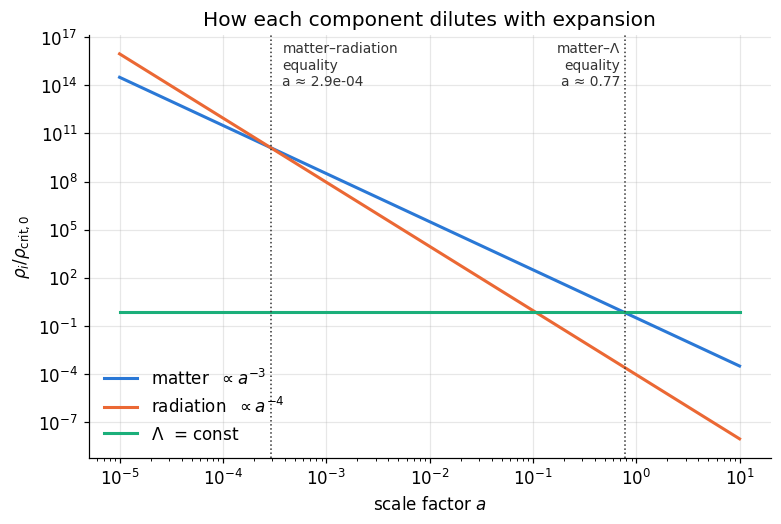

matter-radiation equality: a = 2.89e-04  (z = 3461)
matter-Lambda   equality: a = 0.772  (z = 0.30)


In [8]:
a = np.logspace(-5, 1, 400)
Om, Or, OL = 0.315, 9.1e-5, 0.685         # present-day values

fig, ax = plt.subplots()
ax.loglog(a, Om * a**-3, color=BLUE,   label=r"matter  $\propto a^{-3}$")
ax.loglog(a, Or * a**-4, color=ORANGE, label=r"radiation  $\propto a^{-4}$")
ax.loglog(a, OL * np.ones_like(a), color=AQUA, label=r"$\Lambda$  = const")
a_eq = Or / Om; a_mL = (Om / OL)**(1/3)
for x in (a_eq, a_mL): ax.axvline(x, color=INK, lw=1, ls=":")
ax.text(a_eq*1.3, 1e14, f"matter–radiation\nequality\na ≈ {a_eq:.1e}", fontsize=9, color=INK)
ax.text(a_mL*0.9, 1e14, f"matter–Λ\nequality\na ≈ {a_mL:.2f}", fontsize=9, color=INK, ha="right")
ax.set_xlabel("scale factor $a$"); ax.set_ylabel(r"$\rho_i / \rho_{\rm crit,0}$")
ax.set_title("How each component dilutes with expansion"); ax.legend(frameon=False, loc="lower left")
plt.show()
print(f"matter-radiation equality: a = {a_eq:.2e}  (z = {1/a_eq-1:.0f})")
print(f"matter-Lambda   equality: a = {a_mL:.3f}  (z = {1/a_mL-1:.2f})")

### 2.4 Acceleration equation

Differentiate $\dot a^2 = \frac{8\pi G}{3}\rho a^2 - kc^2$ with respect to time:

$$
2\dot a\ddot a = \frac{8\pi G}{3}\left(\dot\rho a^2 + 2\rho a\dot a\right).
$$

Insert the fluid equation $\dot\rho a^2 = -3a\dot a\left(\rho + p/c^2\right)$ and divide by $2a\dot a$:

$$
\frac{\ddot a}{a} = \frac{4\pi G}{3}\left[-3\left(\rho + \frac{p}{c^2}\right) + 2\rho\right]
\quad\Longrightarrow\quad
\boxed{\;\frac{\ddot a}{a} = -\frac{4\pi G}{3}\left(\rho + \frac{3p}{c^2}\right)\;}
$$


### 2.5 Critical density and density parameters

For a flat Universe ($k=0$):

$$
H^2 = \frac{8\pi G}{3}\rho \quad\Longrightarrow\quad \rho_\text{crit} = \frac{3H^2}{8\pi G}.
$$

The density parameter of each component is the ratio of its density to the critical density:

$$
\Omega_i = \frac{\rho_i}{\rho_\text{crit}} = \frac{8\pi G\rho_i}{3H^2}.
$$


In [4]:
H0_SI = 67.4e3 / Mpc
rho_crit = 3 * H0_SI**2 / (8 * np.pi * G)
m_p = 1.6726e-27
print(f"rho_crit,0 = {rho_crit:.3e} kg/m^3  ≈ {rho_crit/m_p:.1f} protons per m^3")

rho_crit,0 = 8.533e-27 kg/m^3  ≈ 5.1 protons per m^3


Dividing the Friedmann equation by $H_0^2$ and writing every density relative to today:

$$
\frac{H^2}{H_0^2} = \Omega_r\left(\frac{a}{a_0}\right)^{-4} + \Omega_m\left(\frac{a}{a_0}\right)^{-3} + \Omega_k\left(\frac{a}{a_0}\right)^{-2} + \Omega_\Lambda,
\qquad
\Omega_k = -\frac{kc^2}{a_0^2H_0^2},
$$

and at $a = a_0$ this gives following relation

$$
\Omega_m + \Omega_r + \Omega_\Lambda + \Omega_k = 1 .
$$


In [9]:
def E(a, Om, Or=0.0, OL=0.0):
    "Dimensionless Hubble rate H(a)/H0 (with a0 = 1)."
    Ok = 1 - Om - Or - OL
    return np.sqrt(Or * a**-4 + Om * a**-3 + Ok * a**-2 + OL)

### 2.6 Time as a function of the scale factor

From $\dot a = aH$:

$$
\frac{da}{dt} = a H_0 E(a)
\quad\Longrightarrow\quad
t(a) = \int_0^{a} \frac{da'}{a' H_0 \sqrt{\Omega_r a'^{-4} + \Omega_m a'^{-3} + \Omega_k a'^{-2} + \Omega_\Lambda}} .
$$

### 2.7 Analytic solution: flat, matter-only Universe

With $\Omega_m = 1$, $\Omega_r = \Omega_\Lambda = \Omega_k = 0$ (Einstein–de Sitter), and more generally keeping $\Omega_m$ as a symbol:

$$
\left(\frac{da}{dt}\right)^2 = H_0^2\,\Omega_m\, a^{-1}
\;\Longrightarrow\;
a^{1/2}\,da = H_0\sqrt{\Omega_m}\,dt
\;\Longrightarrow\;
\frac23 a^{3/2} = H_0\sqrt{\Omega_m}\,t + C .
$$

Choosing $t = 0$ today, $a(0)=1$ gives $C = \frac23$, hence

$$
\boxed{\;a(t) = \left(\frac32\sqrt{\Omega_m}\,H_0 t + 1\right)^{2/3}\;}
$$


## 3. Numerical methods

Most differential equations have no closed-form solution, so we approximate them step by step.

$$
\frac{dy}{dt} = f(t, y) = H_0\sqrt{\frac{\Omega_m}{y}},\qquad y(0) = 1 .
$$


In the tests below $H_0 = 0.67$ in arbitrary inverse time units so the solution covers a large range of $y$ within $t \in [0, 10]$.

### 3.1 Euler's method (1768)

$$
y_{n+1} = y_n + h\,f(t_n, y_n), \qquad h = t_{n+1} - t_n .
$$

### 3.2 Fourth-order Runge–Kutta (Runge 1895, Kutta 1901)

$$
\begin{aligned}
k_1 &= h f(t_n, y_n), & k_2 &= h f\!\left(t_n + \tfrac h2,\; y_n + \tfrac{k_1}{2}\right),\\
k_3 &= h f\!\left(t_n + \tfrac h2,\; y_n + \tfrac{k_2}{2}\right), & k_4 &= h f(t_n + h,\; y_n + k_3),\\
y_{n+1} &= y_n + \tfrac16\left(k_1 + 2k_2 + 2k_3 + k_4\right).
\end{aligned}
$$


In [10]:
def euler(f, y0, t):
    "Explicit Euler for y' = f(t, y) on the grid t."
    y = np.zeros(len(t)); y[0] = y0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        y[n+1] = y[n] + h * f(t[n], y[n])
    return y

def rk4(f, y0, t):
    "Classical 4th-order Runge-Kutta for y' = f(t, y) on the grid t."
    y = np.zeros(len(t)); y[0] = y0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        k1 = h * f(t[n],         y[n])
        k2 = h * f(t[n] + h/2,   y[n] + k1/2)
        k3 = h * f(t[n] + h/2,   y[n] + k2/2)
        k4 = h * f(t[n] + h,     y[n] + k3)
        y[n+1] = y[n] + (k1 + 2*k2 + 2*k3 + k4) / 6
    return y

def grid(a, b, h):
    "Uniform grid from a to b (inclusive) with step h."
    N = int(round((b - a) / h))
    return a + h * np.arange(N + 1)

H_test, Om_test, y0 = 0.67, 1.0, 1.0
f = lambda t, y: H_test * np.sqrt(Om_test / y)
exact = lambda t: (1.5 * np.sqrt(Om_test) * H_test * t + y0)**(2/3)

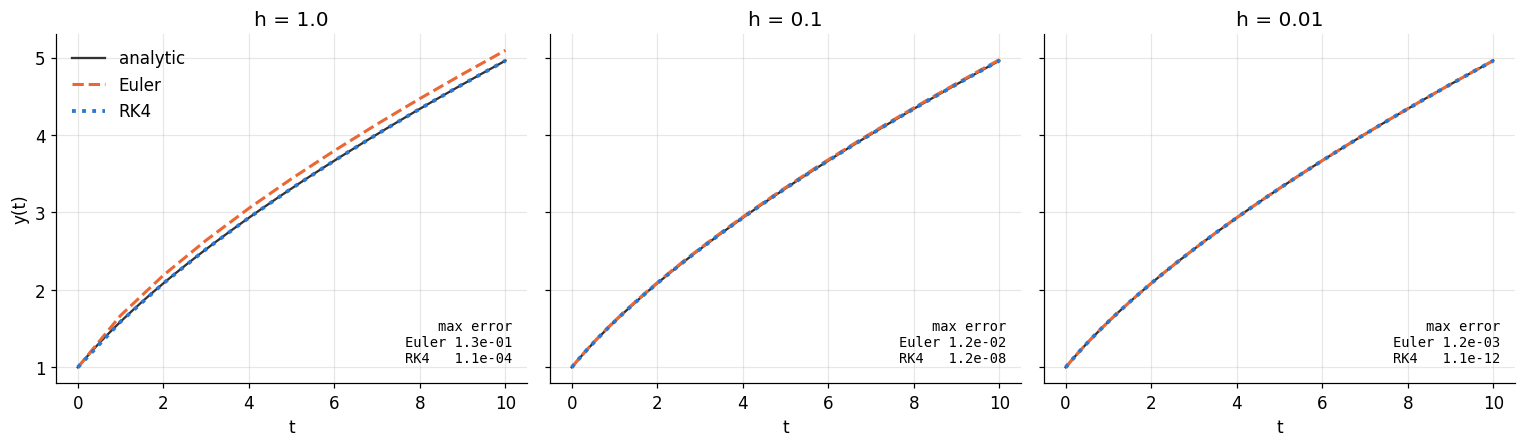

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, h in zip(axes, [1.0, 0.1, 0.01]):
    t = grid(0, 10, h)
    ye, yr = euler(f, y0, t), rk4(f, y0, t)
    tt = np.linspace(0, 10, 400)
    ax.plot(tt, exact(tt), color=INK, lw=1.5, label="analytic")
    ax.plot(t, ye, "--", color=ORANGE, label="Euler")
    ax.plot(t, yr, ":",  color=BLUE, lw=2.5, label="RK4")
    ax.set_title(f"h = {h}")
    ax.set_xlabel("t")
    ax.text(0.97, 0.05,
            f"max error\nEuler {np.max(abs(ye-exact(t))):.1e}\nRK4   {np.max(abs(yr-exact(t))):.1e}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9, family="monospace")
axes[0].set_ylabel("y(t)"); axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

With $h = 1$ Euler visibly overshoots, while RK4 is already almost exact. Halving the step halves Euler's error but reduces RK4's error by a factor $\approx 16$. To measure the **order** $p$ of each method (error $\propto h^p$) we plot the maximum global error against $h$ on log–log axes and fit the slope:

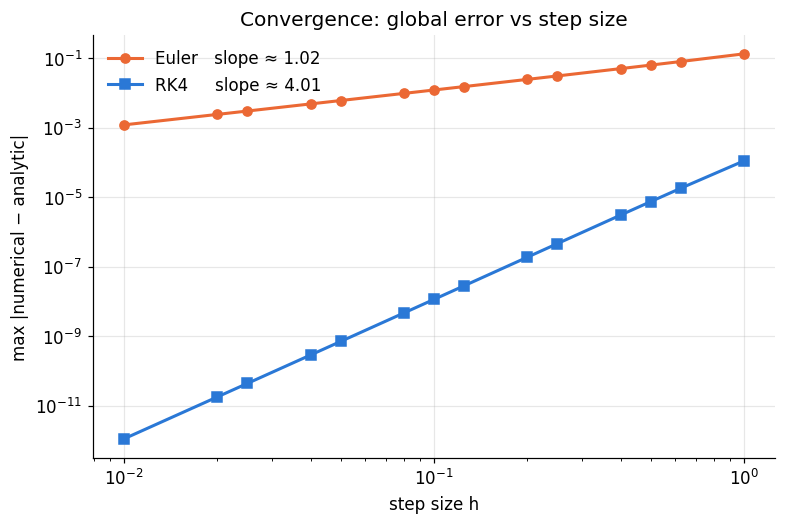

Order of Euler ≈ 1.02  (theory: 1)
Order of RK4   ≈ 4.01  (theory: 4)


In [8]:
hs = 10 / np.array([10, 16, 20, 25, 40, 50, 80, 100, 125, 200, 250, 400, 500, 1000])  # steps that divide [0,10] exactly
err_e, err_r = [], []
for h in hs:
    t = grid(0, 10, h)
    err_e.append(np.max(abs(euler(f, y0, t) - exact(t))))
    err_r.append(np.max(abs(rk4(f, y0, t)   - exact(t))))
err_e, err_r = np.array(err_e), np.array(err_r)

p_e = np.polyfit(np.log(hs), np.log(err_e), 1)[0]
p_r = np.polyfit(np.log(hs), np.log(err_r), 1)[0]

fig, ax = plt.subplots()
ax.loglog(hs, err_e, "o-", color=ORANGE, ms=6, label=f"Euler   slope ≈ {p_e:.2f}")
ax.loglog(hs, err_r, "s-", color=BLUE,   ms=6, label=f"RK4     slope ≈ {p_r:.2f}")
ax.set_xlabel("step size h"); ax.set_ylabel("max |numerical − analytic|")
ax.set_title("Convergence: global error vs step size"); ax.legend(frameon=False)
plt.show()
print(f"Order of Euler ≈ {p_e:.2f}  (theory: 1)")
print(f"Order of RK4   ≈ {p_r:.2f}  (theory: 4)")

### 3.3 Second-order equations

For $\ddot y = F(t, y, \dot y)$ introduce $z = \dot y$ and solve the first-order system

$$
\dot y = z \equiv f(t,y,z), \qquad \dot z = F(t, y, z) \equiv g(t,y,z).
$$

**Euler:** $\;y_{n+1} = y_n + h f(t_n,y_n,z_n),\quad z_{n+1} = z_n + h g(t_n,y_n,z_n).$

**RK4:**

$$
\begin{aligned}
k_1 &= hf(t_n, y_n, z_n), & l_1 &= hg(t_n, y_n, z_n),\\
k_2 &= hf\!\left(t_n+\tfrac h2, y_n+\tfrac{k_1}2, z_n+\tfrac{l_1}2\right), & l_2 &= hg\!\left(t_n+\tfrac h2, y_n+\tfrac{k_1}2, z_n+\tfrac{l_1}2\right),\\
k_3 &= hf\!\left(t_n+\tfrac h2, y_n+\tfrac{k_2}2, z_n+\tfrac{l_2}2\right), & l_3 &= hg\!\left(t_n+\tfrac h2, y_n+\tfrac{k_2}2, z_n+\tfrac{l_2}2\right),\\
k_4 &= hf(t_n+h, y_n+k_3, z_n+l_3), & l_4 &= h\,\mathbf{g}(t_n+h, y_n+k_3, z_n+l_3),
\end{aligned}
$$
$$
y_{n+1} = y_n + \tfrac16(k_1+2k_2+2k_3+k_4),\qquad z_{n+1} = z_n + \tfrac16(l_1+2l_2+2l_3+l_4).
$$


### 3.4 Second Friedmann equation in terms of $y = a/a_0$

Using $\frac{\ddot a}{a} = -\frac{4\pi G}{3}\left(\rho + \frac{3p}{c^2}\right) + \frac{\Lambda c^2}{3}$ with $p_m = 0$, $p_r = \rho_r c^2/3$, $p_\Lambda = -\rho_\Lambda c^2$, and $\frac{8\pi G}{3}\rho_{i,0} = H_0^2\Omega_i$:

$$
\boxed{\;\ddot y = -\frac{H_0^2}{2}\left(\frac{\Omega_m}{y^2} + \frac{2\,\Omega_r}{y^3}\right) + H_0^2\,\Omega_\Lambda\, y\;}
$$

with initial conditions from the first Friedmann equation:

$$
y(0) = 1, \qquad \dot y(0) = H_0\sqrt{\Omega_m + \Omega_r + \Omega_k + \Omega_\Lambda} = H_0 .
$$


In [13]:
def euler_system(F, s0, t):
    "Euler for a first-order system s' = F(t, s), s = [y, z]."
    s = np.zeros((len(t), len(s0))); s[0] = s0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        s[n+1] = s[n] + h * F(t[n], s[n])
    return s

def rk4_system(F, s0, t, stop=None):
    "RK4 for s' = F(t, s). Works for negative steps (backwards in time). Optional stop(s) -> True ends the run."
    s = np.full((len(t), len(s0)), np.nan); s[0] = s0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        k1 = h * F(t[n],       s[n])
        k2 = h * F(t[n] + h/2, s[n] + k1/2)
        k3 = h * F(t[n] + h/2, s[n] + k2/2)
        k4 = h * F(t[n] + h,   s[n] + k3)
        s[n+1] = s[n] + (k1 + 2*k2 + 2*k3 + k4) / 6
        if stop is not None and stop(s[n+1]):
            break
    return s

def friedmann_rhs(H0, Om, Or=0.0, OL=0.0):
    "Right-hand side of the second Friedmann equation as a first-order system [y, z=y']."
    def F(t, s):
        y, z = s
        return np.array([z, -0.5 * H0**2 * (Om / y**2 + 2 * Or / y**3) + H0**2 * OL * y])
    return F

# check: the 2nd-order system must reproduce the analytic Einstein-de Sitter solution
t = grid(0, 10, 0.1)
F = friedmann_rhs(H_test, 1.0)
for name, solver in [("Euler", euler_system), ("RK4", rk4_system)]:
    y = solver(F, np.array([1.0, H_test]), t)[:, 0]
    print(f"{name:5s} (2nd-order form, h=0.1): max error = {np.max(abs(y - exact(t))):.2e}")

Euler (2nd-order form, h=0.1): max error = 7.88e-02
RK4   (2nd-order form, h=0.1): max error = 2.27e-06


## 4. Relative size of the Universe as a function of cosmic time

We integrate the second Friedmann equation with RK4 forwards (to $+30$ Gyr) and backwards (to $-15$ Gyr) from today, with $H_0 = 67.4$ km/s/Mpc and step $h = 1/96$ Gyr. The integration stops when $y$ drops below $10^{-3}$ (the Big Bang or Big Crunch), because the equation is singular at $y=0$.


| Model | $\Omega_m$ | $\Omega_\Lambda$ | $\Omega_r$ | $\Omega_k = 1-\sum$ | Geometry |
|---|---|---|---|---|---|
| ΛCDM | 0.3 | 0.7 | 0.0001 | ≈ 0 | flat |
| Open, matter only | 0.3 | 0 | 0.0001 | ≈ +0.7 |*open ($k=-1$) |
| Closed | 5 | 0 | 0.001 | ≈ −4 | closed ($k=+1$) |
| Einstein–de Sitter | 1 | 0 | 0.0001 | ≈ 0 | flat |



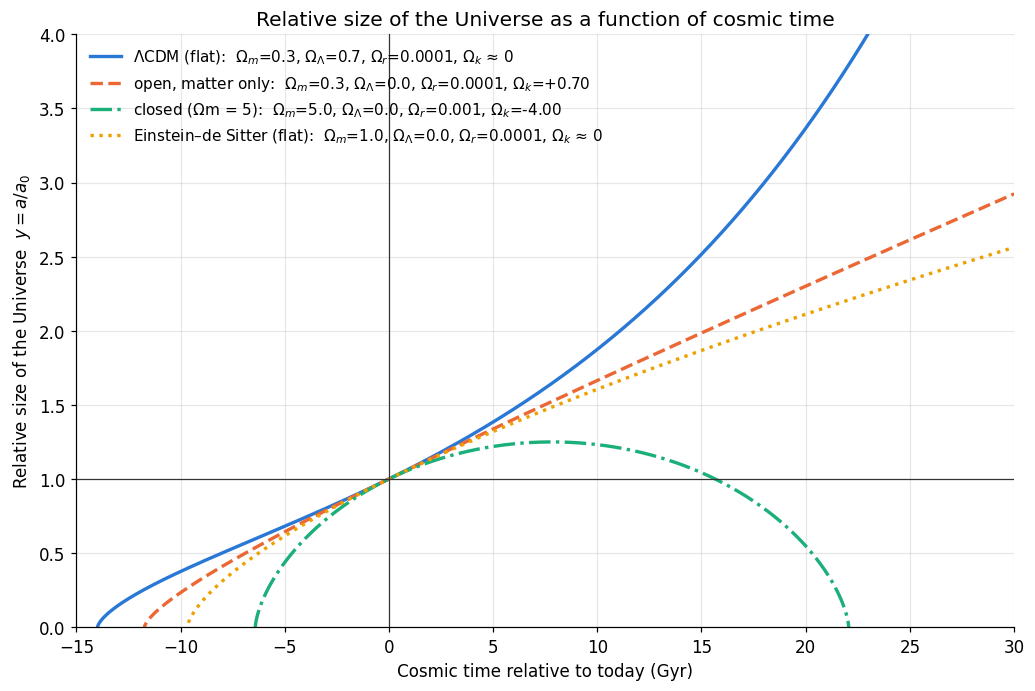

In [14]:
H0 = H0_to_per_Gyr(67.4)   # Gyr^-1
h = 1 / 96                 # Gyr

models = [ 
    ("ΛCDM (flat)",               0.3, 0.7, 1e-4, BLUE,   "-"),
    ("open, matter only",         0.3, 0.0, 1e-4, ORANGE, "--"),
    ("closed (Ωm = 5)",           5.0, 0.0, 1e-3, AQUA,   "-."),
    ("Einstein–de Sitter (flat)", 1.0, 0.0, 1e-4, YELLOW, ":"),
]

t_fwd = grid(0,  30, h)
t_bwd = grid(0, -15, -h)  # negative step
stop = lambda s: (not np.isfinite(s[0])) or s[0] < 1e-3

results = {}
for name, Om, OL, Or, col, ls in models:
    Ok = 1 - Om - OL - Or
    F = friedmann_rhs(H0, Om, Or, OL)
    s0 = np.array([1.0, H0 * E(1.0, Om, Or, OL)])
    y_f = rk4_system(F, s0, t_fwd, stop)[:, 0]
    y_b = rk4_system(F, s0, t_bwd, stop)[:, 0]
    results[name] = (y_b, y_f, Om, OL, Or, Ok)

fig, ax = plt.subplots(figsize=(11, 7))
for (name, Om, OL, Or, col, ls) in models:
    y_b, y_f, *_ , Ok = results[name]
    t_all = np.concatenate([t_bwd[::-1], t_fwd[1:]])
    y_all = np.concatenate([y_b[::-1],   y_f[1:]])
    ax.plot(t_all, y_all, color=col, ls=ls, lw=2.2,
            label=f"{name}:  $\\Omega_m$={Om}, $\\Omega_\\Lambda$={OL}, $\\Omega_r$={Or}, $\\Omega_k$" + (" ≈ 0" if abs(Ok) < 5e-3 else f"={Ok:+.2f}"))
ax.axhline(1, color=INK, lw=0.8); ax.axvline(0, color=INK, lw=0.8)
ax.set_xlim(-15, 30); ax.set_ylim(0, 4)
ax.set_xlabel("Cosmic time relative to today (Gyr)")
ax.set_ylabel("Relative size of the Universe  $y = a/a_0$")
ax.set_title("Relative size of the Universe as a function of cosmic time")
ax.legend(frameon=False, loc="upper left", fontsize=10)
plt.show()

**Checking the numerics.** The time at which each backward curve reaches $y = 0$ is that model's age. For the matter-only models the ages are known exactly, so we can compare RK4 with the analytic results and with SciPy's adaptive integrator:

* Einstein–de Sitter: $t_0 = \dfrac{2}{3H_0}$.
* Closed, matter only ($\Omega_m > 1$), parametric solution:
  $\;a(\theta) = \dfrac{\Omega_m}{2(\Omega_m-1)}(1-\cos\theta),\quad H_0 t(\theta) = \dfrac{\Omega_m}{2(\Omega_m-1)^{3/2}}(\theta - \sin\theta),$
  with the Big Crunch at $\theta = 2\pi$.

In [15]:
def age_from_curve(t, y):
    "Time at which the RK4 curve leaves y > 1e-3 (first NaN or tiny value)."
    ok = np.isfinite(y) & (y > 1e-3)
    return t[ok][-1] if not ok.all() else np.nan

def event_time(Om, OL, Or, direction):
    F = friedmann_rhs(H0, Om, Or, OL)
    ev = lambda t, s: s[0] - 1e-3; ev.terminal = True
    sol = solve_ivp(F, (0, direction * 100), [1.0, H0 * E(1.0, Om, Or, OL)],
                    method="DOP853", rtol=1e-11, atol=1e-13, events=ev)
    return sol.t_events[0][0] if len(sol.t_events[0]) else np.nan

print(f"{'model':28s} {'Big Bang (RK4)':>15s} {'(solve_ivp)':>12s} {'Big Crunch (RK4)':>17s} {'(solve_ivp)':>12s}")
for (name, Om, OL, Or, *_ ) in models:
    y_b, y_f, *_ = results[name]
    print(f"{name:28s} {age_from_curve(t_bwd, y_b):15.3f} {event_time(Om, OL, Or, -1):12.3f} "
          f"{age_from_curve(t_fwd, y_f):17.3f} {event_time(Om, OL, Or, +1):12.3f}")

# analytic checks (matter only)
print(f"\nEinstein–de Sitter analytic age 2/(3H0)            = {2/(3*H0):.3f} Gyr")
Om = 5.0
A, B = Om / (2*(Om-1)), Om / (2*(Om-1)**1.5)
theta0 = np.arccos(1 - 1/A)              # a = 1 on the expanding branch
t_bang  = B * (theta0 - np.sin(theta0)) / H0
t_total = B * 2*np.pi / H0
print(f"Closed Ωm=5 analytic: Big Bang {t_bang:.3f} Gyr ago, Big Crunch in {t_total - t_bang:.3f} Gyr, "
      f"maximum size y = {2*A:.3f} at +{B*np.pi/H0 - t_bang:.2f} Gyr")

model                         Big Bang (RK4)  (solve_ivp)  Big Crunch (RK4)  (solve_ivp)
ΛCDM (flat)                          -13.979      -13.980               nan          nan
open, matter only                    -11.729      -11.729               nan          nan
closed (Ωm = 5)                       -6.406       -6.410            22.062       22.064
Einstein–de Sitter (flat)             -9.667       -9.670               nan          nan

Einstein–de Sitter analytic age 2/(3H0)            = 9.672 Gyr
Closed Ωm=5 analytic: Big Bang 6.412 Gyr ago, Big Crunch in 22.073 Gyr, maximum size y = 1.250 at +7.83 Gyr


### What does the plot show?

* ΛCDM (blue, solid) — the model that best matches observations (WMAP and Planck measured the Universe to be spatially flat to within ~0.5%). Early on matter dominates and the expansion decelerates; once the constant dark-energy density takes over, the expansion accelerates and grows exponentially, $a \propto e^{H_0\sqrt{\Omega_\Lambda}\,t}$. Integrating this curve from $y=0$ to $y=1$ gives the age of the Universe (Section 5).
* Open, matter only (orange, dashed) — not flat: $\Omega_k \approx 0.7$, so $k=-1$. It expands forever and at late times approaches coasting, $a \propto t$ (a straight line), because the matter term dies off faster ($a^{-3}$) than the curvature term ($a^{-2}$).
* Closed (aqua, dash-dot) — $\Omega_m = 5 > 1$, so $k = +1$. After the expansion phase gravity wins, the Universe reaches a maximum size and recollapses into a Big Crunch. Some speculative models ("Big Bounce") suggest a new expansion could follow, but standard cosmology says nothing about what happens at the singularity.
* Einstein–de Sitter (yellow, dotted) — flat, matter only, density exactly critical: $a \propto t^{2/3}$, decelerating forever but never stopping.

## 5. Age of the Universe

$$
t_0 = \int_0^1 \frac{da}{a\,H(a)} = \frac{1}{H_0}\int_0^1 \frac{da}{\sqrt{\Omega_r a^{-2} + \Omega_m a^{-1} + \Omega_k + \Omega_\Lambda a^2}} .
$$

First, the original calculation with the Planck 2015 parameters $\Omega_m = 0.3086$, $\Omega_\Lambda = 0.6914$, $H_0 = 67.74$ km/s/Mpc:

In [16]:
def age(H0_kms, Om, OL, Or=0.0):
    Ok = 1 - Om - OL - Or
    integrand = lambda a: 1 / np.sqrt(Or / a**2 + Om / a + Ok + OL * a**2)
    I, err = quad(integrand, 0, 1, epsabs=0, epsrel=1e-12)
    return I / H0_to_per_Gyr(H0_kms)

print(f"Original (no radiation):        t0 = {age(67.74, 0.3086, 0.6914):.3f} Gyr")

Or = 4.18e-5 / 0.6774**2
print(f"With radiation (Ωr = {Or:.1e}): t0 = {age(67.74, 0.3086, 0.6914 - Or, Or):.3f} Gyr")
print(f"Planck 2015 published value:    t0 = 13.799 ± 0.021 Gyr")

Original (no radiation):        t0 = 13.807 Gyr
With radiation (Ωr = 9.1e-05): t0 = 13.801 Gyr
Planck 2015 published value:    t0 = 13.799 ± 0.021 Gyr


The original result (13.81 Gyr) is correct for $\Omega_r = 0$. Including the real radiation density lowers it by about 6 million years and reproduces the published Planck 2015 value.

The tiny difference between this notebook's 13.807 and the original 13.808 comes from the Mpc value ($3.0857$ vs $3.086\times10^{22}$ m) and the length of the year used.

### How much does the answer depend on the model?

In [13]:
cases = [("ΛCDM, Planck 2015", 67.74, 0.3086, 0.6914),
         ("Einstein–de Sitter", 67.74, 1.0, 0.0),
         ("Open, matter only Ωm=0.3", 67.74, 0.3, 0.0),
         ("ΛCDM, H0 = 73 (local distance ladder)", 73.0, 0.3086, 0.6914)]
for name, H, Om, OL in cases:
    print(f"{name:40s} t0 = {age(H, Om, OL):6.2f} Gyr")

ΛCDM, Planck 2015                        t0 =  13.81 Gyr
Einstein–de Sitter                       t0 =   9.62 Gyr
Open, matter only Ωm=0.3                 t0 =  11.67 Gyr
ΛCDM, H0 = 73 (local distance ladder)    t0 =  12.81 Gyr


Without dark energy the flat model gives only 9.6 Gyr, younger than the oldest stars (12–13 Gyr). The ~8% difference between $H_0 = 67.7$ and $73$ km/s/Mpc translates directly into a ~8% difference in age.

### When did the expansion start to accelerate?

From the acceleration equation, $\ddot a = 0$ when $\Omega_m a^{-3} = 2\Omega_\Lambda$ (ignoring radiation). The present deceleration parameter is $q_0 = -\frac{\ddot a\, a}{\dot a^2}\big|_0 = \frac{\Omega_m}{2} + \Omega_r - \Omega_\Lambda$.

In [14]:
Om, OL = 0.3086, 0.6914
a_acc = (Om / (2*OL))**(1/3)
I, _ = quad(lambda a: 1/np.sqrt(Om/a + OL*a**2), 0, a_acc)
t_acc = I / H0_to_per_Gyr(67.74)
print(f"acceleration began at a = {a_acc:.3f}  (redshift z = {1/a_acc - 1:.2f}),  "
      f"{t_acc:.2f} Gyr after the Big Bang, {age(67.74, Om, OL) - t_acc:.2f} Gyr ago")
print(f"q0 = {Om/2 - OL:.3f}  (negative = accelerating today)")

acceleration began at a = 0.607  (redshift z = 0.65),  7.62 Gyr after the Big Bang, 6.19 Gyr ago
q0 = -0.537  (negative = accelerating today)


## 6. Conclusion

* The Friedmann equation $H^2 = \frac{8\pi G}{3}\rho - \frac{kc^2}{a^2}$ can be derived from Newtonian gravity plus energy conservation. The Newtonian derivation gives the correct form, but the meaning of $k$ as spatial curvature, and the role of pressure in the acceleration equation, come from general relativity.
* Combining it with the fluid equation gives $\rho \propto a^{-3(1+w)}$ and the acceleration equation $\ddot a/a = -\frac{4\pi G}{3}(\rho + 3p/c^2) + \frac{\Lambda c^2}{3}$.
* For a flat matter-only Universe $a \propto t^{2/3}$. Euler and RK4 both converge to this solution, with measured orders ≈ 1 and ≈ 4, so RK4 is far more efficient for the same accuracy.
* Integrating the second Friedmann equation shows how the fate of the Universe depends on its content: open and flat matter-only models expand forever, a closed model recollapses, and $\Lambda$ makes the expansion accelerate.
* With Planck 2015 parameters the age of the Universe is **13.80 Gyr**. The Newtonian derivation does not produce a cosmological constant, but without dark energy the age would be about 9.6 Gyr (inconsistent with the oldest stars) so $\Lambda$ must be added.

## 7. Bibliography

1. A. Liddle, *An Introduction to Modern Cosmology*, 2nd ed., Wiley, 2003.
2. J. B. Hartle, *Gravity: An Introduction to Einstein's General Relativity*, Addison-Wesley, 2003 (Polish ed. *Grawitacja*).
3. B. Ryden, *Introduction to Cosmology*, 2nd ed., Cambridge University Press, 2017.
4. Planck Collaboration (2016), "Planck 2015 results. XIII. Cosmological parameters", *Astronomy & Astrophysics* 594, A13.
5. A. Friedmann (1922), "Über die Krümmung des Raumes", *Zeitschrift für Physik* 10, 377–386.
6. E. Hubble (1929), "A relation between distance and radial velocity among extra-galactic nebulae", *PNAS* 15, 168–173.
7. W. H. Press, S. A. Teukolsky, W. T. Vetterling, B. P. Flannery, *Numerical Recipes: The Art of Scientific Computing*, 3rd ed., Cambridge University Press, 2007, Ch. 17.
8. R. L. Burden, J. D. Faires, A. M. Burden, *Numerical Analysis*, 10th ed., Cengage Learning, 2016, Ch. 5.
9. L. Euler, *Institutionum calculi integralis*, vol. 1, St Petersburg, 1768.
10. A. G. Riess et al. (2022), "A Comprehensive Measurement of the Local Value of the Hubble Constant with 1 km/s/Mpc Uncertainty from the Hubble Space Telescope and the SH0ES Team", *The Astrophysical Journal Letters* 934, L7.
11. D. Scolnic et al. (2022), "The Pantheon+ Analysis: The Full Data Set and Light-curve Release", *The Astrophysical Journal* 938, 113. Data: https://github.com/PantheonPlusSH0ES/DataRelease
12. D. Brout et al. (2022), "The Pantheon+ Analysis: Cosmological Constraints", *The Astrophysical Journal* 938, 110.